# Prediksi Gaji dengan Regresi Linier

dataset: https://www.kaggle.com/datasets/rhythmghai/250k-job-salary-prediction-dataset/data

## Import Libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import r2_score
import statsmodels.formula.api as smf

import warnings
warnings.filterwarnings('ignore')

## Load Dataset

In [ ]:
# (Opsional) upload file langsung dari komputer
from google.colab import files
uploaded = files.upload()

In [ ]:
df = pd.read_csv('job_salary_prediction_dataset.csv')
df

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069
...,...,...,...,...,...,...,...,...,...,...
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467


In [ ]:
df.head(5)

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
0,AI Engineer,10,Bachelor,2,Healthcare,Medium,India,Hybrid,2,109413
1,Data Analyst,5,Bachelor,17,Telecom,Small,Australia,No,0,93764
2,Frontend Developer,18,PhD,4,Media,Medium,Singapore,No,1,148123
3,Business Analyst,19,PhD,13,Retail,Medium,Canada,Yes,0,189123
4,Product Manager,15,Bachelor,7,Manufacturing,Large,Sweden,Yes,0,165069


In [ ]:
df.tail(5)

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
249995,Software Engineer,17,PhD,2,Telecom,Enterprise,India,No,1,127791
249996,Frontend Developer,20,PhD,7,Telecom,Startup,Remote,No,2,154593
249997,Business Analyst,1,Bachelor,12,Retail,Enterprise,India,Yes,0,75988
249998,Data Scientist,0,High School,2,Consulting,Small,Sweden,Hybrid,5,90467
249999,Data Analyst,16,Diploma,2,Technology,Medium,UK,No,5,133084


In [ ]:
df.sample(10)

,job_title,experience_years,education_level,skills_count,industry,company_size,location,remote_work,certifications,salary
138573,Product Manager,19,PhD,19,Finance,Small,USA,Yes,4,243733
248637,Backend Developer,4,PhD,10,Technology,Enterprise,Germany,Yes,2,179673
210614,Backend Developer,16,Bachelor,16,Media,Medium,Netherlands,Yes,4,149322
192813,Data Scientist,1,High School,15,Consulting,Enterprise,Netherlands,Hybrid,5,134396
209377,Frontend Developer,2,Master,8,Consulting,Startup,Sweden,Yes,5,104058
170622,Data Scientist,15,Diploma,18,Government,Startup,Australia,Hybrid,4,135534
191668,Business Analyst,0,Master,10,Telecom,Enterprise,Canada,Yes,5,152616
205731,Backend Developer,17,Bachelor,14,Healthcare,Startup,UK,Hybrid,3,153855
224834,Frontend Developer,12,Diploma,16,Manufacturing,Enterprise,Sweden,Hybrid,2,155300
70427,DevOps Engineer,6,Bachelor,2,Telecom,Small,India,Yes,2,79598


In [ ]:
df.columns

Index(['job_title', 'experience_years', 'education_level', 'skills_count',
       'industry', 'company_size', 'location', 'remote_work', 'certifications',
       'salary'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 10 columns):
 #   Column            Non-Null Count   Dtype 
---  ------            --------------   ----- 
 0   job_title         250000 non-null  object
 1   experience_years  250000 non-null  int64 
 2   education_level   250000 non-null  object
 3   skills_count      250000 non-null  int64 
 4   industry          250000 non-null  object
 5   company_size      250000 non-null  object
 6   location          250000 non-null  object
 7   remote_work       250000 non-null  object
 8   certifications    250000 non-null  int64 
 9   salary            250000 non-null  int64 
dtypes: int64(4), object(6)
memory usage: 19.1+ MB


In [ ]:
df.describe()

,experience_years,skills_count,certifications,salary
count,250000.000000,250000.000000,250000.000000,250000.000000
mean,10.005408,9.997812,2.491928,145718.080524
std,6.060602,5.479288,1.706475,37407.952729
min,0.000000,1.000000,0.000000,31867.000000
25%,5.000000,5.000000,1.000000,119358.000000
50%,10.000000,10.000000,2.000000,143453.000000
75%,15.000000,15.000000,4.000000,169492.000000
max,20.000000,19.000000,5.000000,333046.000000


## Data Preparation

In [ ]:
obj = df.select_dtypes(include=['object', 'string'])
num = df.select_dtypes(exclude=['object', 'string'])

In [ ]:
obj

,job_title,education_level,industry,company_size,location,remote_work
0,AI Engineer,Bachelor,Healthcare,Medium,India,Hybrid
1,Data Analyst,Bachelor,Telecom,Small,Australia,No
2,Frontend Developer,PhD,Media,Medium,Singapore,No
3,Business Analyst,PhD,Retail,Medium,Canada,Yes
4,Product Manager,Bachelor,Manufacturing,Large,Sweden,Yes
...,...,...,...,...,...,...
249995,Software Engineer,PhD,Telecom,Enterprise,India,No
249996,Frontend Developer,PhD,Telecom,Startup,Remote,No
249997,Business Analyst,Bachelor,Retail,Enterprise,India,Yes
249998,Data Scientist,High School,Consulting,Small,Sweden,Hybrid


In [ ]:
num

,experience_years,skills_count,certifications,salary
0,10,2,2,109413
1,5,17,0,93764
2,18,4,1,148123
3,19,13,0,189123
4,15,7,0,165069
...,...,...,...,...
249995,17,2,1,127791
249996,20,7,2,154593
249997,1,12,0,75988
249998,0,2,5,90467


In [ ]:
num.isna().sum()

,0
experience_years,0
skills_count,0
certifications,0
salary,0


In [ ]:
num.isna().any().sum()

np.int64(0)

In [ ]:
obj.isna().sum()

,0
job_title,0
education_level,0
industry,0
company_size,0
location,0
remote_work,0


In [ ]:
num.duplicated().value_counts()

,count
False,249878
True,122


In [ ]:
num.duplicated().sum()

np.int64(122)

In [ ]:
df.duplicated().sum()

np.int64(0)

# Bagian 1: Regresi Linier Sederhana
Variabel independen (X) = `experience_years` (lama pengalaman, tahun)
Variabel dependen (Y) = `salary` (gaji)

Persamaan regresi: **y = a + bx**, dengan

$$b = \frac{n\sum xy - \sum x \sum y}{n\sum x^2 - (\sum x)^2} \qquad a = \bar{y} - b\bar{x}$$

### 1. Hitung rata-rata, Σx, Σy, Σxy, Σx², Σy²

In [ ]:
# diubah ke float agar tidak overflow saat penjumlahan/perkalian angka besar
x = df['experience_years'].astype(float)
y = df['salary'].astype(float)

n = len(df)
x_mean = x.mean()
y_mean = y.mean()
sum_x = x.sum()
sum_y = y.sum()
sum_xy = (x*y).sum()
sum_x2 = (x**2).sum()
sum_y2 = (y**2).sum()

print('n       =', n)
print('x rata  =', x_mean)
print('y rata  =', y_mean)
print('Σx      =', sum_x)
print('Σy      =', sum_y)
print('Σxy     =', sum_xy)
print('Σx²     =', sum_x2)
print('Σy²     =', sum_y2)

n       = 250000
x rata  = 10.005408
y rata  = 145718.080524
Σx      = 2501352.0
Σy      = 36429520131.0
Σxy     = 389296242487.0
Σx²     = 34209736.0
Σy²     = 5658277080393151.0


### 2. Hitung b dan a

In [ ]:
b = (n*sum_xy - sum_x*sum_y) / (n*sum_x2 - sum_x**2)
a = y_mean - b*x_mean

print('b (slope)     =', b)
print('a (intercept) =', a)

b (slope)     = 2701.172954225089
a (intercept) = 118691.74303841265


### 3. Bentuk model regresi linier sederhana

In [ ]:
print(f'salary = {a:.2f} + {b:.2f} * experience_years')

salary = 118691.74 + 2701.17 * experience_years


### 4. Cek hasil manual dengan sklearn dan statsmodels

In [ ]:
lr = LinearRegression()
lr.fit(df[['experience_years']], y)
print('Intercept sklearn:', lr.intercept_)
print('Slope sklearn    :', lr.coef_[0])

Intercept sklearn: 118691.74303841262
Slope sklearn    : 2701.1729542250923


In [ ]:
simple_ols = smf.ols('salary ~ experience_years', data=df).fit()
print(simple_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.192
Model:                            OLS   Adj. R-squared:                  0.192
Method:                 Least Squares   F-statistic:                 5.922e+04
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        07:00:33   Log-Likelihood:            -2.9606e+06
No. Observations:              250000   AIC:                         5.921e+06
Df Residuals:                  249998   BIC:                         5.921e+06
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         1.187e+05    129.843  

### 5. Prediksi gaji untuk pengalaman tertentu

In [ ]:
pengalaman = 5
prediksi = a + b*pengalaman
print(f'Prediksi gaji dengan pengalaman {pengalaman} tahun = {prediksi:.2f}')

Prediksi gaji dengan pengalaman 5 tahun = 132197.61


### 6. Koefisien korelasi (r)
$$r = \frac{n\sum xy - \sum x \sum y}{\sqrt{(n\sum x^2 - (\sum x)^2)(n\sum y^2 - (\sum y)^2)}}$$

| Nilai r | Korelasi |
|---|---|
| 0,0 – 0,29 | Sangat Lemah |
| 0,3 – 0,49 | Lemah |
| 0,5 – 0,69 | Cukup |
| 0,7 – 0,79 | Kuat |
| 0,8 – 1,00 | Sangat Kuat |

In [ ]:
r = (n*sum_xy - sum_x*sum_y) / np.sqrt((n*sum_x2 - sum_x**2) * (n*sum_y2 - sum_y**2))

def kategori_korelasi(r):
    k = abs(r)
    if k < 0.3: return 'Sangat Lemah'
    elif k < 0.5: return 'Lemah'
    elif k < 0.7: return 'Cukup'
    elif k < 0.8: return 'Kuat'
    else: return 'Sangat Kuat'

arah = 'searah (positif)' if r > 0 else 'berlawanan arah (negatif)'
print('r manual  =', r)
print('r pandas  =', x.corr(y))
print(f'Korelasi {kategori_korelasi(r)} dan {arah}.')

r manual  = 0.4376271392904724
r pandas  = 0.4376271392904727
Korelasi Lemah dan searah (positif).


### 7. Koefisien determinasi (r²)

In [ ]:
r2 = r**2
print('r² =', r2)
print(f'Lama pengalaman menjelaskan {r2*100:.2f}% variasi gaji, sedangkan {(1-r2)*100:.2f}% dipengaruhi variabel lain.')

r² = 0.19151751304356254
Lama pengalaman menjelaskan 19.15% variasi gaji, sedangkan 80.85% dipengaruhi variabel lain.


### 8. Plot regresi linier (scatter + garis regresi)
Scatter hanya memakai 2.000 sampel acak agar plot terbaca; garis dihitung dari seluruh data.

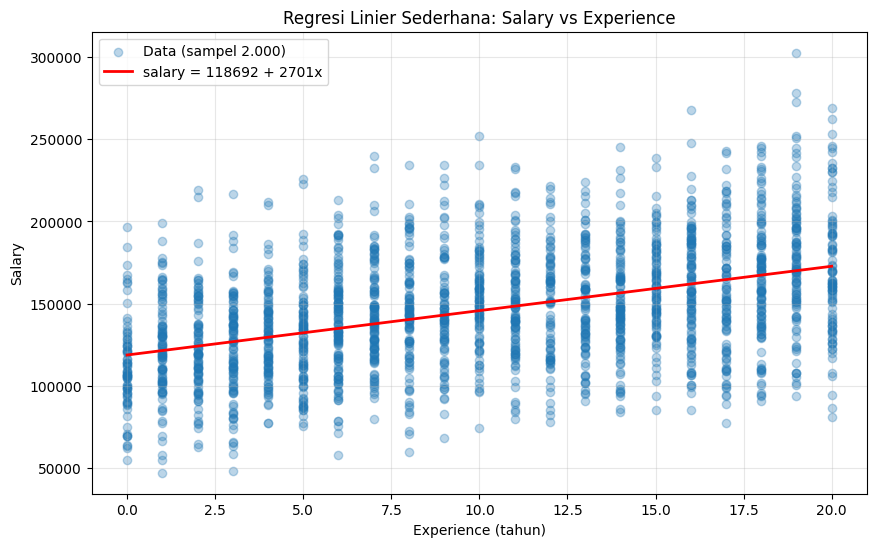

In [ ]:
sampel = df.sample(2000, random_state=42)

plt.figure(figsize=(10, 6))
plt.scatter(sampel['experience_years'], sampel['salary'], alpha=0.3, label='Data (sampel 2.000)')

x_line = np.array([x.min(), x.max()])
plt.plot(x_line, a + b*x_line, color='red', linewidth=2, label=f'salary = {a:.0f} + {b:.0f}x')

plt.xlabel('Experience (tahun)')
plt.ylabel('Salary')
plt.title('Regresi Linier Sederhana: Salary vs Experience')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Bagian 2: Regresi Linier Berganda (Pengembangan)
Pada bagian 1, pengalaman kerja hanya menjelaskan sebagian kecil variasi gaji. Pada bagian ini semua variabel dimasukkan agar prediksi lebih akurat.

### Encoding Variabel Kategorikal
Regresi linier hanya bisa memproses angka, sedangkan kolom teks (`job_title`, `education_level`, `industry`, `company_size`, `location`, `remote_work`) tidak bisa langsung dipakai. Karena itu kolom-kolom ini diubah dengan **One-Hot Encoding**: setiap kategori menjadi kolom 0/1 tersendiri.

`drop_first=True` membuang satu kategori per kolom sebagai pembanding (baseline), supaya tidak terjadi multikolinearitas sempurna.

In [ ]:
# Jumlah kategori tiap kolom teks
obj.nunique()

,0
job_title,12
education_level,5
industry,10
company_size,5
location,10
remote_work,3


In [ ]:
categorical_features = list(obj.columns)
numerical_features = ['experience_years', 'skills_count', 'certifications']

x = pd.get_dummies(df[numerical_features + categorical_features], columns=categorical_features, drop_first=True, dtype=float)
y = df['salary']

print('Jumlah fitur setelah encoding:', x.shape[1])
x.head()

Jumlah fitur setelah encoding: 42


,experience_years,skills_count,certifications,job_title_Backend Developer,job_title_Business Analyst,job_title_Cloud Engineer,job_title_Cybersecurity Analyst,job_title_Data Analyst,job_title_Data Scientist,job_title_DevOps Engineer,...,location_Germany,location_India,location_Netherlands,location_Remote,location_Singapore,location_Sweden,location_UK,location_USA,remote_work_No,remote_work_Yes
0,10,2,2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,5,17,0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,18,4,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3,19,13,0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,15,7,0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


## OLS Regression Result
Semua variabel dimasukkan: numerik langsung, kategorikal dengan `C(...)` (statsmodels melakukan one-hot encoding otomatis).

In [ ]:
statMDL = smf.ols('salary ~ C(job_title) + C(education_level) + C(industry) + C(company_size) + C(location) + C(remote_work) + experience_years + skills_count + certifications', data=df).fit()
print(statMDL.summary())

                            OLS Regression Results                            
Dep. Variable:                 salary   R-squared:                       0.963
Model:                            OLS   Adj. R-squared:                  0.963
Method:                 Least Squares   F-statistic:                 1.566e+05
Date:                Fri, 09 Oct 2026   Prob (F-statistic):               0.00
Time:                        07:03:02   Log-Likelihood:            -2.5737e+06
No. Observations:              250000   AIC:                         5.148e+06
Df Residuals:                  249957   BIC:                         5.148e+06
Df Model:                          42                                         
Covariance Type:            nonrobust                                         
                                                coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------

## Linier Regression Model

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.50, random_state=42)
l = LinearRegression()
l.fit(x_train, y_train)

LinearRegression()

## Prediction Result

In [ ]:
predictions = l.predict(x_test)

print('Coefficients: ', l.coef_)
print('Intercept: ', l.intercept_)
print('MAE: ', metrics.mean_absolute_error(y_test, predictions))
print('MSE: ', metrics.mean_squared_error(y_test, predictions))
print('RMSE: ', np.sqrt(metrics.mean_squared_error(y_test, predictions)))
accuracy = l.score(x_test, y_test)
print('Accuracy: ', accuracy*100, '%')
print('R2: ', r2_score(y_test, predictions))

Coefficients:  [ 2.69975892e+03  8.57497121e+02  1.63311228e+03 -3.42406083e+04
 -5.14997928e+04 -2.14278002e+04 -2.45701946e+04 -5.36992614e+04
 -2.68797074e+04 -2.36654584e+04 -4.07156226e+04 -1.06140233e+04
 -1.59835441e+04 -3.21086154e+04 -5.36440644e+03 -1.07484717e+04
  1.08363775e+04  2.15267136e+04  4.77798457e+01  1.12682009e+02
  7.81312927e+01  2.71275755e+01 -1.49167434e+01  6.86728536e+01
  5.38398666e+01  8.01640963e+01 -4.62219008e+01 -1.41012673e+04
 -2.82400397e+04 -3.53304238e+04 -4.24056883e+04  2.79195022e+04
  1.39791218e+04 -4.19015746e+04 -4.20227502e+01 -1.36902657e+01
 -1.34881569e+01 -3.69024609e+01  2.09540024e+04  4.19858610e+04
 -1.44923898e+01  5.32111476e+03]
Intercept:  146629.86782851574
MAE:  5463.196038253087
MSE:  51386015.80061436
RMSE:  7168.403992564478
Accuracy:  96.32586137712576 %
R2:  0.9632586137712575


In [ ]:
print('Train set accuracy: ', r2_score(y_train, l.predict(x_train))*100, '%')
print('Test set accuracy: ', r2_score(y_test, predictions)*100, '%')

Train set accuracy:  96.34948553759673 %
Test set accuracy:  96.32586137712576 %


In [ ]:
# Koefisien per fitur (setelah encoding)
coef_df = pd.DataFrame({'Fitur': x.columns, 'Koefisien': l.coef_}).sort_values('Koefisien', ascending=False)
coef_df

,Fitur,Koefisien
39,location_USA,41985.860951
31,location_Canada,27919.502235
17,education_level_PhD,21526.713646
38,location_UK,20954.002396
32,location_Germany,13979.121810
16,education_level_Master,10836.377488
41,remote_work_Yes,5321.114755
0,experience_years,2699.758919
2,certifications,1633.112283
1,skills_count,857.497121


In [ ]:
df2 = pd.DataFrame({'Actual': y_test, 'Predicted': predictions})
df2['Error'] = df2['Actual'] - df2['Predicted']
df2

,Actual,Predicted,Error
38683,164009,172696.624702,-8687.624702
64939,79594,89132.300473,-9538.300473
3954,74090,63860.081867,10229.918133
120374,177193,168229.579686,8963.420314
172861,120012,117317.862820,2694.137180
...,...,...,...
60372,132055,139737.862823,-7682.862823
182219,149735,152577.958414,-2842.958414
43490,179316,180051.535630,-735.535630
99683,151778,150595.306072,1182.693928


## Scatter Plots

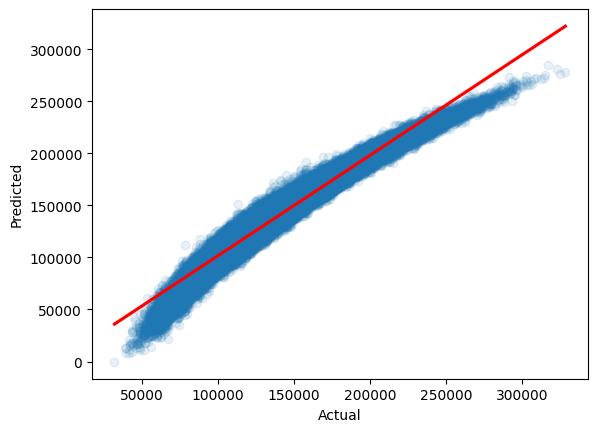

In [ ]:
sns.regplot(x=y_test, y=predictions, scatter_kws={'alpha':0.1}, line_kws={'color':'red'})
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.show()

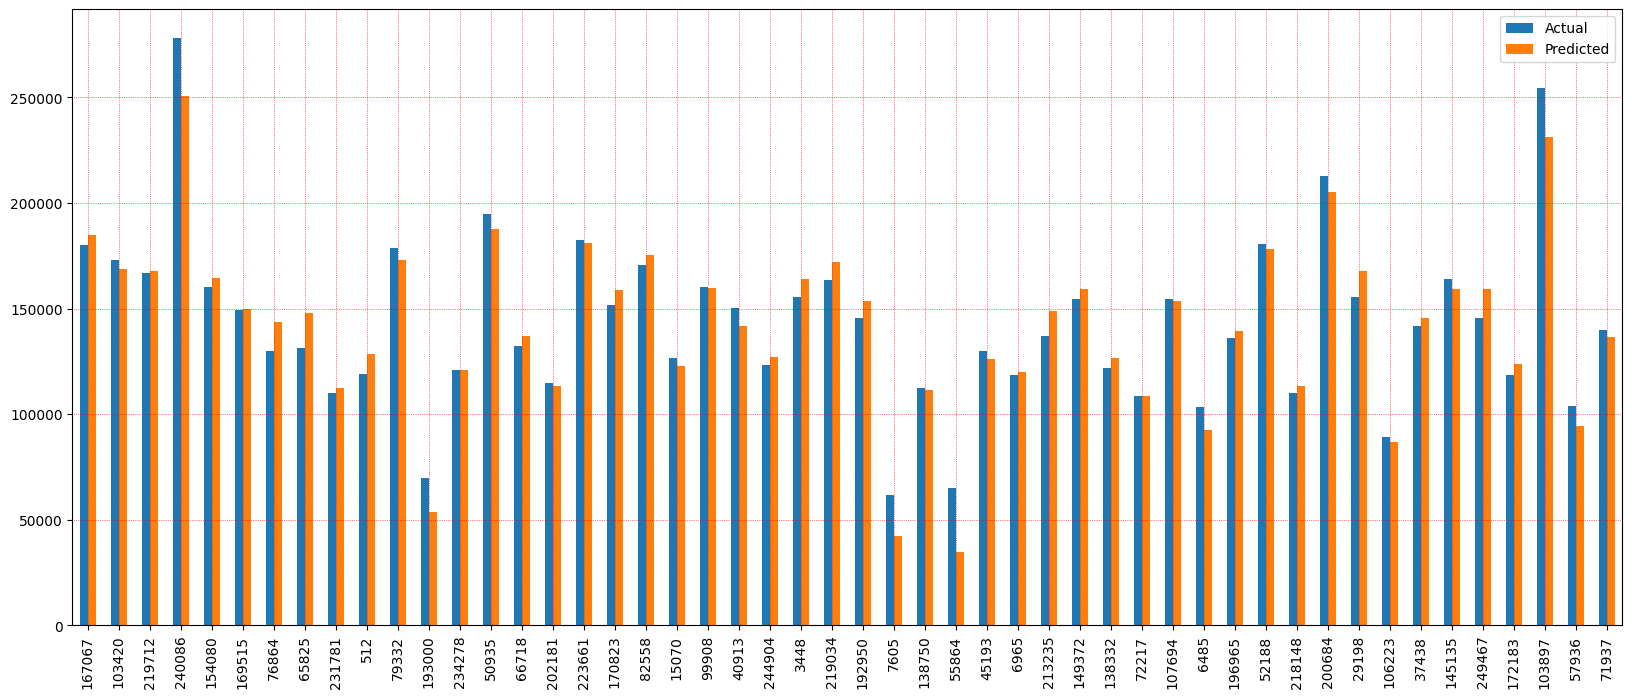

In [ ]:
# Data uji ada ~125.000 baris, jadi bar chart hanya memakai 50 sampel acak agar terbaca
df2_plot = pd.DataFrame({'Actual': y_test, 'Predicted': predictions}).sample(50, random_state=42)

df2_plot.plot(kind='bar', figsize=(20, 8))
plt.grid(which='major', linestyle='-', linewidth='0.5', color='green')
plt.grid(which='major', linestyle=':', linewidth='0.5', color='red')
plt.show()

## New Prediction
Data baru ditulis dalam bentuk asli (sebelum encoding), lalu di-encode dengan kolom yang sama seperti data latih.

In [ ]:
new_observation = pd.DataFrame([{
    'experience_years': 5,
    'skills_count': 10,
    'certifications': 2,
    'job_title': 'Data Scientist',
    'education_level': 'Master',
    'industry': 'Technology',
    'company_size': 'Large',
    'location': 'USA',
    'remote_work': 'Hybrid'
}])

# encode dengan kolom yang sama seperti data latih (kategori yang tidak ada diisi 0)
new_encoded = pd.get_dummies(new_observation, columns=categorical_features, dtype=float).reindex(columns=x.columns, fill_value=0)

l.predict(new_encoded)

array([183891.286084])

## Perbandingan Regresi Sederhana vs Berganda

In [ ]:
perbandingan = pd.DataFrame({
    'Model': ['Sederhana (experience_years)', 'Berganda (semua variabel)'],
    'R2': [r2, r2_score(y_test, predictions)]
})
perbandingan

,Model,R2
0,Sederhana (experience_years),0.191518
1,Berganda (semua variabel),0.963259
